<a href="https://colab.research.google.com/github/Tabatha651/METODOS_NUMERICOS/blob/main/metodoDeNeville.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
#18/nov/2026

#MÉTODO DE NEVILLE

##¿Qué es el Método de Neville?
El Método de Neville es un algoritmo utilizado para realizar una interpolación polinómica. Su objetivo es encontrar el valor aproximado de una función $f(x)$ en un punto específico $x$, a partir de un conjunto de puntos conocidos $(x_0, f(x_0)), (x_1, f(x_1)), \dots, (x_n, f(x_n))$, los cuales llamaremos a $x_i$ nodos

##¿Para qué sirve?
Nos ayuda a calcular directamente el valor numérico del polinomio evaluado en el punto $x$ de interes. También nos permite aumentar la precisión de forma progresiva, aprovechando  así los cálculos de polinomios de grado menor para construir los de grado mayor

También nos facilita observar la convergencia, ya que al comparar los resultados conforme avanza el grado del polinomio en la tabla, se puede verificar si las aproximaciones estan yendo hacia un valor concreto

In [15]:

"MÉTODO DE NEVILLE"

x=1.5  #Valor donde queremos aproximar
#       x0,  x1,  x2,  x3,  x4
nodos=[1.0, 1.3, 1.6, 1.9, 2.2]
f_x=[0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]   #Q[i][0]=f_x[i]

#n = 4
n=len(nodos)-1

#Creamos la tabla Q vacía de 5x5 llena de ceros
Q = [[0.0 for i in range(n+1)] for i in range(n + 1)]

#Llenamos la primera columna Q[i][0] con los valores de f_x
for i in range(n+1):
  Q[i][0]=f_x[i]

for i in range(1, n+1):  #Para i=1, 2, ..., n
  for j in range(1, i+1):  #para j=1, 2, ..., i
    Q[i][j] = ((x-nodos[i-j]) * Q[i][j-1] - (x-nodos[i])*Q[i-1][j-1]) / (nodos[i] - nodos[i-j])

## ¿Cómo funciona la iteración?
El algoritmo organiza los cálculos en forma de una **tabla triangular** ($Q$) donde cada columna representa un grado mayor de aproximación:

1. **Columna 0 (Grado 0):** Se colocan los valores iniciales conocidos $Q_{i,0} = f(x_i)$.
2. **Columnas siguientes (Grado $j = 1, 2, \dots, n$):** Cada nueva aproximación $Q_{i,j}$ se calcula combinando de manera ponderada dos aproximaciones de la columna anterior ($Q_{i,j-1}$ y $Q_{i-1,j-1}$) mediante la siguiente fórmula recursiva:

$$Q_{i,j} = \frac{(x - x_{i-j})Q_{i,j-1} - (x - x_i)Q_{i-1,j-1}}{x_i - x_{i-j}}$$




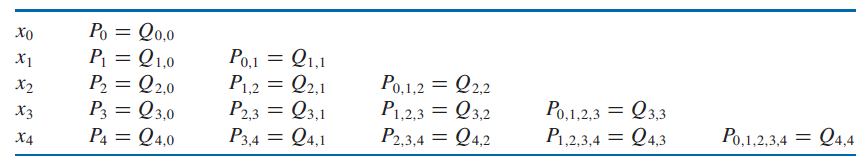

In [17]:
"IMPRESIÓN DE TABLA"
print("x_i | Grado 0 | Grado 1 | Grado 2 | Grado 3 | Grado 4")
print("-------------------------------------------------------")

for i in range(n+1):          # Recorremos cada fila de la tabla (desde i=0 hasta n)

  print(nodos[i], end=" | ")        #Imprimimos el valor de x al inicio de la fila, sin saltar de línea (end=" | ") (end sirve para que escriba en la misma linea)

  for j in range(i + 1):                #Imprimimos cada valor calculado de esa fila (desde j=0 hasta i)

    valor_redondeado=round(Q[i][j], 7)
    print(valor_redondeado, end=" ")

  print()                               #Al terminar los números de esa fila, hacemos un salto de línea para pasar a la siguiente


print("---------------------------------------------------")
print("Resultado final:", round(Q[n][n], 7))

x_i | Grado 0 | Grado 1 | Grado 2 | Grado 3 | Grado 4
-------------------------------------------------------
1.0 | 0.7651977 
1.3 | 0.620086 0.5233449 
1.6 | 0.4554022 0.5102968 0.5124715 
1.9 | 0.2818186 0.5132634 0.5112857 0.5118127 
2.2 | 0.1103623 0.510427 0.5137361 0.5118302 0.51182 
---------------------------------------------------
Resultado final: 0.51182


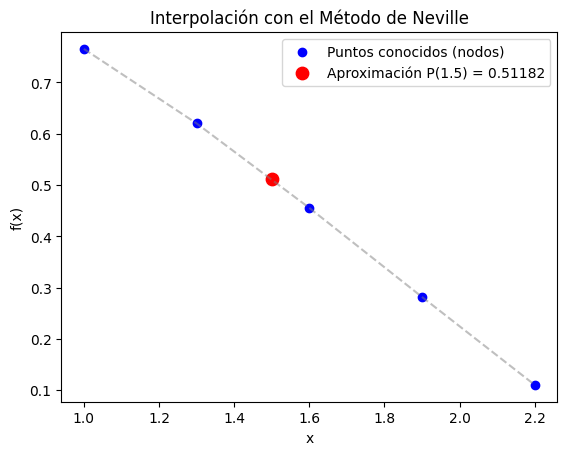

In [18]:
import matplotlib.pyplot as plt

#Graficamos los puntos conocidos (nodos)
plt.scatter(nodos, f_x, color="blue", label="Puntos conocidos (nodos)")

#Graficamos el punto aproximado con Neville
plt.scatter(x, Q[n][n], color="red", s=80, label=f"Aproximación P({x}) = {Q[n][n]:.5f}")

#Conectamos los nodos con una línea
plt.plot(nodos, f_x, color="gray", linestyle="--", alpha=0.5)

plt.title("Interpolación con el Método de Neville")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend()
plt.show()